# Driver-gene benchmark: results and figures (version 2)

Rebuilds every table and figure from the CSV files in `../results/`; nothing heavy runs here. Everything uses the
**current method (version 2: K = 3 rollout steps, per-fate ranking)** and the **44 held-out synthetic decisions**:
bifurcation and trifurcation replicates 3–12 (10 each; replicates 0–2 were used to choose the settings and are not
reported, replicates 5–12 were simulated afterwards, 5 Nov 2026), and all nested-bifurcation (10) and haematopoietic
(14) decisions. Competitors are the real CellRank 2 and the
baselines; CellOracle and CEFCON need a prior network on real gene symbols and cannot run on simulated networks.

**Contents**
1. Setup: paths, method names, colours (one fixed colour and marker per method in every figure)
2. Data: all methods on the 44 held-out decisions
3. Tables per decision
4. Paired comparison: ours vs each method
5. Figure: ours vs selected competitors per scenario (`fig_synthetic_competitors`) **← choose competitors here**
6. Figure 3: all methods (`fig3_method_comparison`)
7. Figure 4: per decision (`fig4_per_decision`)
8. Figure 5: runtime (`fig5_runtime_scaling`)
9. Speed-ups: fast vs exact
10. Real data: LARRY and Nestorowa (`fig_larry`, `fig_nestorowa`) **← choose methods here**
11. Ablation panels (`figures/ablation/`)

**Metric:** AUPRC of drivers against the markers of the same decision. 1.0 = all drivers above all markers;
chance = share of drivers (about 0.08–0.3 depending on the decision).

## 1. Setup

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RES, FIG = ROOT / "results", ROOT / "figures"
FIG.mkdir(exist_ok=True)
pd.set_option("display.precision", 2)

# One entry per method: key in the results files -> (label, colour, marker).
# Colours: validated categorical palette (adjacent pairs pass the colour-blindness checks in this order), fixed per
# method in every figure, never by rank; plus a marker shape so figures also read in greyscale.
METHODS = {
    # published competitors and main baselines: palette slots 1-6, plotted in this order
    "OURS_v2":                         ("Ours",                              "#2a78d6", "o"),
    "CellRank":                        ("CellRank 2",                        "#eb6834", "s"),
    "rf_shap_fixed":                   ("Random forest + SHAP",              "#1baf7a", "D"),
    "de_terminal":                     ("DE (terminal states)",              "#eda100", "^"),
    "CellOracle":                      ("CellOracle",                        "#e87ba4", ">"),   # real data only
    "CEFCON":                          ("CEFCON",                            "#008300", "<"),   # real data only
    # secondary baselines: grey shades, told apart by marker and label
    "fate_corr":                       ("Fate correlation",                  "#6f6e69", "v"),
    "fate_corr_decision_region":       ("Fate corr., undecided cells",       "#8f8e88", "P"),
    "absorption_corr_decision_region": ("Absorption corr., undecided cells", "#5a5955", "X"),
    "obs_counterfactual":              ("Observational counterfactuals",     "#a9a8a2", "h"),
    "random":                          ("Random",                            "#c4c3bd", "."),
}
INK, INK2, GRID_C, AXIS_C = "#0b0b0b", "#3d3d3a", "#ecebe6", "#8a8a85"
STYLE = {"font.family": "DejaVu Sans", "font.size": 8, "axes.spines.top": False, "axes.spines.right": False,
         "axes.edgecolor": AXIS_C, "xtick.color": INK2, "ytick.color": INK2, "axes.labelcolor": INK2,
         "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
         "pdf.fonttype": 42, "ps.fonttype": 42}
plt.rcParams.update(STYLE)


def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=300, bbox_inches="tight")
    fig.savefig(FIG / f"{name}.pdf", bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(FIG / f"{name}.png"), width=900))

## 2. Data: all methods on the 44 held-out decisions
Sources: `v2_heldout.csv` (ours, `eval_v2.py`), `baseline_metrics.csv` and `hsc_metrics.csv` (baselines,
`evaluate.py`), `cellrank_synthetic.csv` (CellRank 2, `evaluate.py --methods CellRank`).
HSC replicate 2, decision D2 is not included: that replicate has only one terminal fate there.
The results files also contain a privileged reference that correlates genes with each cell's *true* future fate
(`ORACLE_early_true_fate`); it is neither a method nor ground truth and is not shown here.

In [2]:
KEY = ["dataset", "decision"]
COLS = KEY + ["model", "method", "auprc_vs_markers", "chance_vs_markers"]
ours = pd.read_csv(RES / "v2_heldout.csv").query("K == 3 and mode == 'perfate'").assign(method="OURS_v2")
held = set(zip(ours.dataset, ours.decision))
others = pd.concat([pd.read_csv(RES / "baseline_metrics.csv"), pd.read_csv(RES / "hsc_metrics.csv"),
                    pd.read_csv(RES / "cellrank_synthetic.csv").assign(method="CellRank")])
others = others[np.array([k in held for k in zip(others.dataset, others.decision)])
                & others.method.isin([m for m in METHODS if m not in ("CellOracle", "CEFCON")]).values]
d = pd.concat([ours[COLS], others[COLS]], ignore_index=True)
d["setting"] = d.model + "-" + d.decision
assert (d.groupby("method").size() == 44).all(), d.groupby("method").size()
d.to_csv(FIG / "all_scores_long.csv", index=False)
LABEL = {k: v[0] for k, v in METHODS.items()}
SHORT = LABEL | {"rf_shap_fixed": "RF + SHAP", "de_terminal": "DE", "fate_corr": "Fate corr.",
                 "fate_corr_decision_region": "Fate corr. (undecided)", "absorption_corr_decision_region": "Absorption corr. (undecided)",
                 "obs_counterfactual": "Obs. counterfactuals"}   # shorter tick labels for figure 3
print(len(held), "decisions;", d.method.nunique(), "methods")

44 decisions; 9 methods


## 3. Tables per decision
Mean AUPRC (± SD over replicates). BF = bifurcation, TF = trifurcation (10 replicates each), CBF = nested
bifurcation (5 replicates, D1 = first, D2 = second decision), HSC = haematopoietic network (Krumsiek 2011;
D1 = MEP vs GMP, D2 = erythrocyte vs megakaryocyte, D3 = monocyte vs granulocyte; 4–5 replicates).

In [3]:
def table(sub):
    m = sub.pivot_table(index="method", columns="setting", values="auprc_vs_markers", aggfunc="mean")
    s = sub.pivot_table(index="method", columns="setting", values="auprc_vs_markers", aggfunc="std")
    order = sub.groupby("method").auprc_vs_markers.mean().sort_values(ascending=False).index
    out = m.loc[order].round(2).astype(str) + " ± " + s.loc[order].round(2).astype(str)
    out["mean (all decisions)"] = sub.groupby("method").auprc_vs_markers.mean().loc[order].round(2)
    out.index = [LABEL[i] for i in order]
    return out

display(table(d[d.model != "HSC"]))
display(table(d[d.model == "HSC"]))
print("chance level per decision:", d[d.method == "OURS_v2"].groupby("setting").chance_vs_markers.mean().round(2).to_dict())

setting,BF-D1,CBF-D1,CBF-D2,TF-D1,mean (all decisions)
Ours,0.89 ± 0.18,0.75 ± 0.24,1.0 ± 0.0,1.0 ± 0.0,0.92
Fate correlation,0.93 ± 0.12,0.32 ± 0.15,0.68 ± 0.18,0.83 ± 0.14,0.75
"Fate corr., undecided cells",0.9 ± 0.15,0.25 ± 0.07,0.64 ± 0.23,0.68 ± 0.23,0.68
CellRank 2,0.6 ± 0.2,0.47 ± 0.14,0.66 ± 0.24,0.8 ± 0.12,0.66
Observational counterfactuals,0.68 ± 0.23,0.61 ± 0.16,0.48 ± 0.17,0.67 ± 0.12,0.63
DE (terminal states),0.46 ± 0.07,0.64 ± 0.25,0.39 ± 0.06,0.53 ± 0.1,0.50
"Absorption corr., undecided cells",0.58 ± 0.26,0.27 ± 0.11,0.48 ± 0.34,0.45 ± 0.27,0.47
Random forest + SHAP,0.43 ± 0.25,0.65 ± 0.26,0.34 ± 0.18,0.47 ± 0.28,0.46
Random,0.17 ± 0.19,0.24 ± 0.2,0.13 ± 0.04,0.21 ± 0.1,0.19


setting,HSC-D1,HSC-D2,HSC-D3,mean (all decisions)
Ours,0.74 ± 0.11,0.6 ± 0.46,0.47 ± 0.37,0.60
Random forest + SHAP,0.66 ± 0.15,0.38 ± 0.23,0.54 ± 0.33,0.53
CellRank 2,0.44 ± 0.1,0.35 ± 0.04,0.72 ± 0.32,0.52
Fate correlation,0.42 ± 0.14,0.4 ± 0.2,0.63 ± 0.4,0.49
Observational counterfactuals,0.36 ± 0.1,0.39 ± 0.05,0.71 ± 0.33,0.49
DE (terminal states),0.56 ± 0.0,0.43 ± 0.14,0.47 ± 0.12,0.49
"Absorption corr., undecided cells",0.42 ± 0.15,0.25 ± 0.06,0.53 ± 0.35,0.41
"Fate corr., undecided cells",0.3 ± 0.22,0.23 ± 0.08,0.64 ± 0.39,0.41
Random,0.15 ± 0.07,0.18 ± 0.1,0.27 ± 0.25,0.20


chance level per decision: {'BF-D1': 0.08, 'CBF-D1': 0.14, 'CBF-D2': 0.09, 'HSC-D1': 0.11, 'HSC-D2': 0.11, 'HSC-D3': 0.11, 'TF-D1': 0.09}


## 4. Paired comparison: ours vs each method
Per decision: does ours score higher? Wins / losses (ties not counted), mean difference, Wilcoxon signed-rank p.

In [4]:
P = d.pivot_table(index=KEY, columns="method", values="auprc_vs_markers")
rows = []
for bench, mask in [("all 44", np.ones(len(P), bool)),
                    ("synthetic (BF, TF, CBF)", ~P.index.get_level_values(0).str.startswith("HSC")),
                    ("haematopoietic (HSC)", P.index.get_level_values(0).str.startswith("HSC"))]:
    for m in [c for c in P.columns if c != "OURS_v2"]:
        diff = (P.loc[mask, "OURS_v2"] - P.loc[mask, m]).dropna()
        nz = diff[diff != 0]
        rows.append({"decisions": bench, "vs": LABEL[m], "n": len(diff), "wins": int((diff > 0).sum()),
                     "losses": int((diff < 0).sum()), "mean diff": diff.mean(),
                     "Wilcoxon p": wilcoxon(nz).pvalue if len(nz) > 5 else np.nan})
pd.DataFrame(rows).round(3)

,decisions,vs,n,wins,losses,mean diff,Wilcoxon p
0,all 44,CellRank 2,44,34,8,0.21,0.00e+00
1,all 44,"Absorption corr., undecided cells",44,34,8,0.37,0.00e+00
2,all 44,DE (terminal states),44,38,5,0.33,0.00e+00
3,all 44,Fate correlation,44,29,9,0.15,7.00e-03
4,all 44,"Fate corr., undecided cells",44,30,8,0.23,1.00e-03
5,all 44,Observational counterfactuals,44,34,9,0.23,0.00e+00
6,all 44,Random,44,41,3,0.63,0.00e+00
7,all 44,Random forest + SHAP,44,33,7,0.34,0.00e+00
8,"synthetic (BF, TF, CBF)",CellRank 2,30,26,2,0.27,0.00e+00
9,"synthetic (BF, TF, CBF)","Absorption corr., undecided cells",30,26,2,0.45,0.00e+00


## 5. Figure: ours vs selected competitors per scenario
**Choose the competitors in `COMPETITORS` below** (any keys of `METHODS`, in the order they should appear; ours is
always drawn first). The same selection is used for figure 4.
Bars = mean AUPRC, points = individual decisions.

In [79]:
#figure setting

y_axis_fontsize =13
tick_size = 13
x_axis_fontsize =11

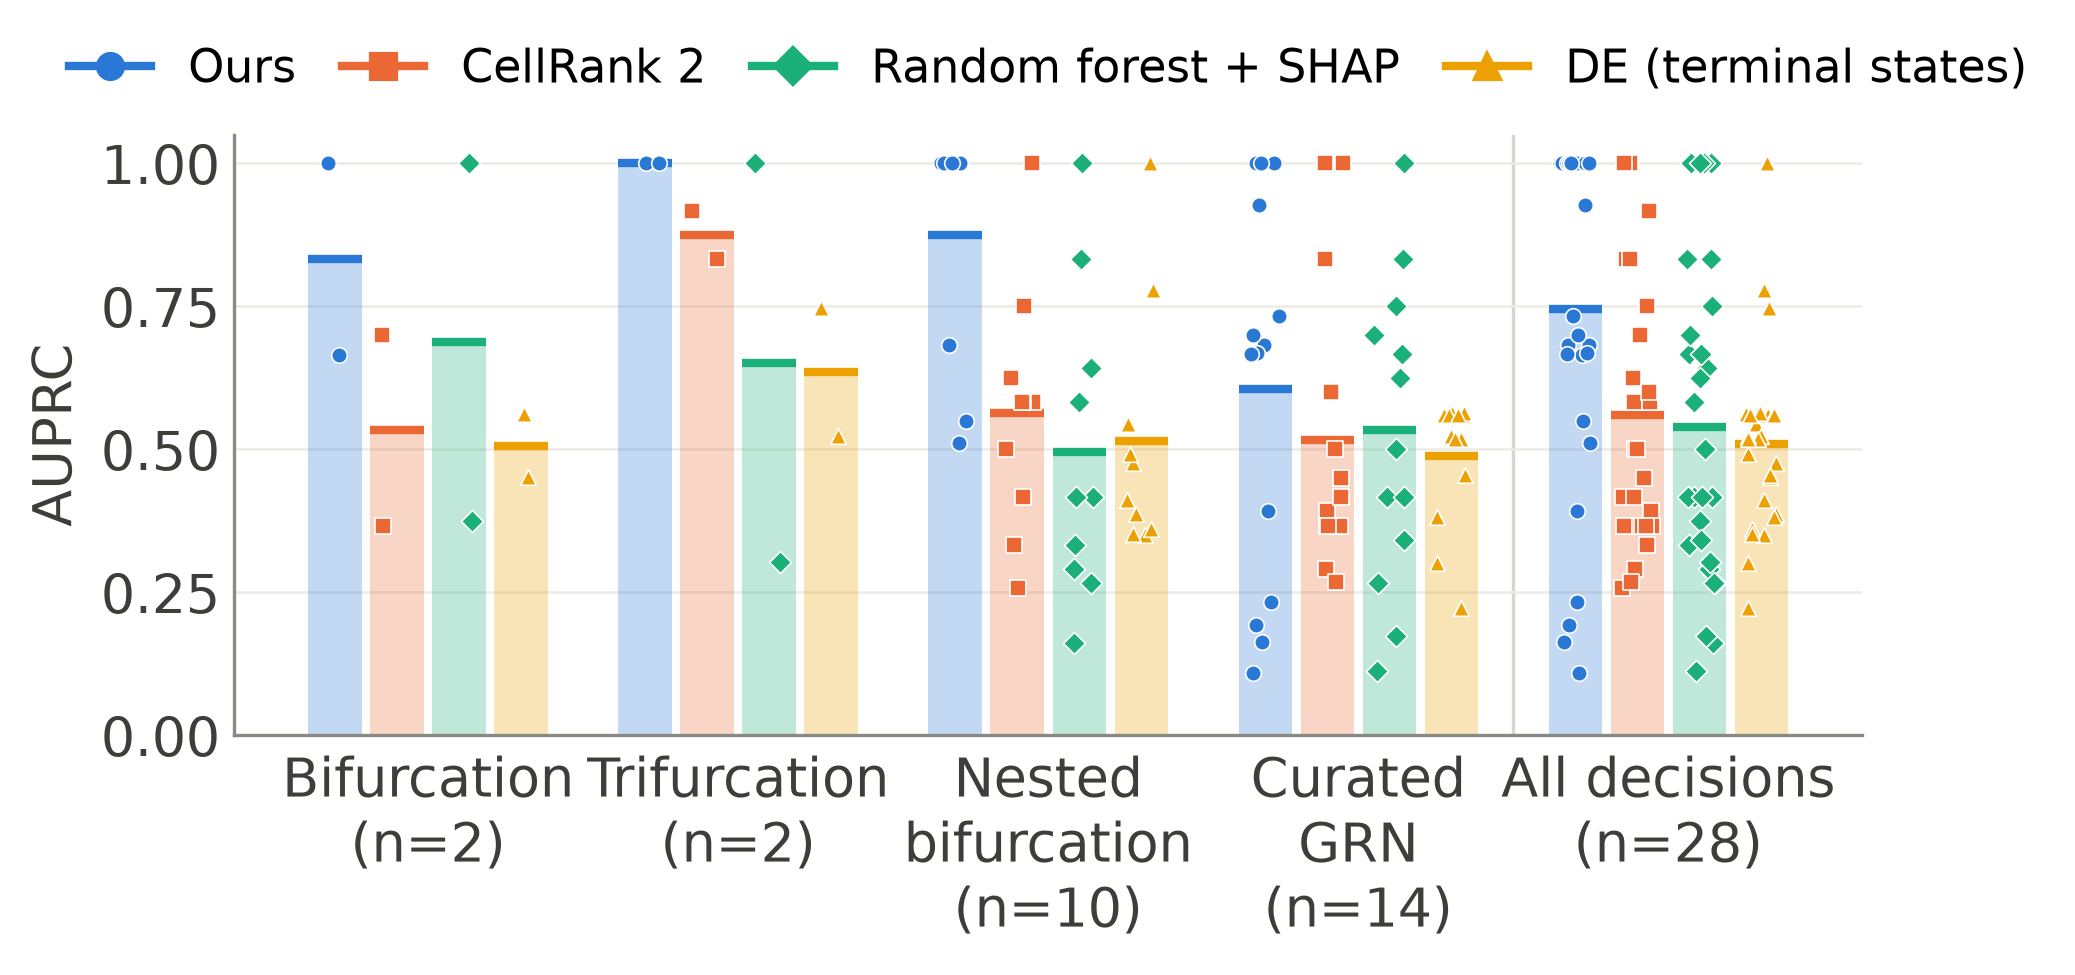

In [80]:
COMPETITORS = ["CellRank", "rf_shap_fixed", "de_terminal"]
# all options: "CellRank", "rf_shap_fixed", "de_terminal", "fate_corr", "fate_corr_decision_region",
#              "absorption_corr_decision_region", "obs_counterfactual", "random"   (CellOracle/CEFCON: real data only)


def grouped_figure(groups, methods, name, width=7.0, height=2.6, all_group=None, seed=0):
    """groups: list of (label, row mask on d). methods: method keys, drawn left to right in every group.
    all_group: optional label for an extra pooled group, separated by a vertical line."""
    groups = groups + ([(all_group, np.ones(len(d), bool))] if all_group else [])
    rng = np.random.default_rng(seed)
    n = len(methods); bw = min(0.8 / n, 0.22)
    fig, ax = plt.subplots(figsize=(width, height))
    labels = []
    for i, (glab, mask) in enumerate(groups):
        sub = d[mask]
        labels.append(f"{glab}\n(n={sub[sub.method == methods[0]].shape[0]})")
        for j, m in enumerate(methods):
            _, col, mar = METHODS[m]
            y = sub[sub.method == m].auprc_vs_markers.values
            x = i + (j - (n - 1) / 2) * bw
            ax.bar(x, y.mean(), bw * 0.86, color=col, alpha=0.28, edgecolor="none", zorder=2)
            ax.hlines(y.mean(), x - bw * 0.43, x + bw * 0.43, colors=col, lw=2, zorder=3)
            ax.scatter(x + rng.uniform(-bw * 0.25, bw * 0.25, len(y)), y, s=14, marker=mar, color=col,
                       edgecolors="white", linewidths=0.4, zorder=4)
    if all_group:
        ax.axvline(len(groups) - 1.5, color="#d6d5cf", lw=0.8, zorder=0)
    ax.set_xticks(range(len(groups)))
    ax.set_xticklabels(labels)
    ax.set_ylim(0, 1.05)
    # Axis label font sizes
    ax.set_ylabel("AUPRC", fontsize=y_axis_fontsize)
    # Tick label font sizes
    ax.tick_params(axis="both", labelsize=tick_size,length=0)

    ax.yaxis.grid(True, color=GRID_C, lw=0.6); ax.set_axisbelow(True);# ax.tick_params(axis="x", length=0)
    h = [plt.Line2D([], [], color=METHODS[m][1], marker=METHODS[m][2], lw=2, markersize=6, label=METHODS[m][0])
         for m in methods]
    ax.legend(handles=h, ncol=min(len(h), 5), loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False,
              handlelength=1.8, columnspacing=1, fontsize=x_axis_fontsize)
    save(fig, name)


SCENARIOS = [("Bifurcation", d.model == "BF"), ("Trifurcation", d.model == "TF"),
             ("Nested\nbifurcation", d.model == "CBF"), ("Curated\nGRN", d.model == "HSC")]
grouped_figure(SCENARIOS, ["OURS_v2"] + COMPETITORS, "fig_synthetic_competitors",
               all_group="All decisions")

## 6. Figure 3: all methods
Every method on the 44 held-out decisions, split into the simulated networks (bifurcation, trifurcation,
nested bifurcation) and the curated haematopoietic network. Methods sorted by their mean over all 44 decisions.
Shaded band = chance level (mean share of drivers).

KeyError: 'ORACLE_early_true_fate'

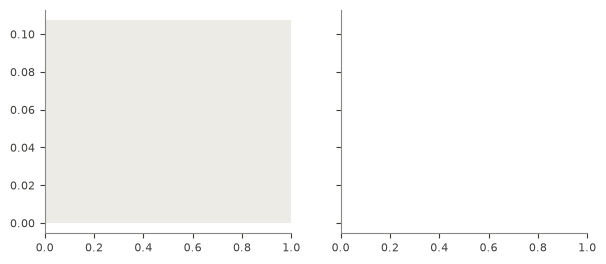

In [83]:
def fig3(methods=None, seed=0):
    order = d.groupby("method").auprc_vs_markers.mean().sort_values(ascending=False).index
    methods = [m for m in order if methods is None or m in methods]
    rng = np.random.default_rng(seed)
    fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.9), sharey=True)
    for ax, (title, mask) in zip(axes, [("Simulated networks (BF, TF, CBF", d.model != "HSC"),
                                         ("Haematopoietic network (HSC", d.model == "HSC")]):
        sub = d[mask]
        title = f"{title}; n={sub[sub.method == 'OURS_v2'].shape[0]})"
        ax.axhspan(0, sub[sub.method == "OURS_v2"].chance_vs_markers.mean(), color=GRID_C, lw=0, zorder=0)
        for i, m in enumerate(methods):
            _, col, mar = METHODS[m]
            y = sub[sub.method == m].auprc_vs_markers.values
            ax.bar(i, y.mean(), 0.72, color=col, alpha=0.28, edgecolor="none", zorder=2)
            ax.hlines(y.mean(), i - 0.36, i + 0.36, colors=col, lw=2, zorder=3)
            ax.scatter(i + rng.uniform(-0.2, 0.2, len(y)), y, s=9, marker=mar, color=col,
                       edgecolors="white", linewidths=0.4, zorder=4)
        ax.set_xticks(range(len(methods)))
        ax.set_xticklabels([SHORT[m] for m in methods], rotation=40, ha="right", rotation_mode="anchor", fontsize=7)
        ax.set_title(title, fontsize=8, loc="left")
        ax.set_ylim(0, 1.05); ax.yaxis.grid(True, color=GRID_C, lw=0.6); ax.set_axisbelow(True)
        ax.tick_params(axis="x", length=0)
        for lab in ax.get_xticklabels():
            if lab.get_text() == SHORT["OURS_v2"]:
                lab.set_fontweight("bold")
    axes[0].set_ylabel("AUPRC, drivers vs markers")
    axes[1].spines["left"].set_visible(False); axes[1].tick_params(axis="y", length=0)
    h = [plt.Rectangle((0, 0), 1, 1, color=GRID_C, label="chance level")]
    fig.legend(handles=h, ncol=1, loc="lower center", bbox_to_anchor=(0.5, 0.98), frameon=False, fontsize=7.5)
    fig.tight_layout()
    save(fig, "fig3_method_comparison")


fig3()          # or e.g. fig3(["OURS_v2", "CellRank", "rf_shap_fixed", "de_terminal", "random"])

## 7. Figure 4: per decision
Same competitors as figure 5 (`COMPETITORS` above), shown for each of the seven decision types.

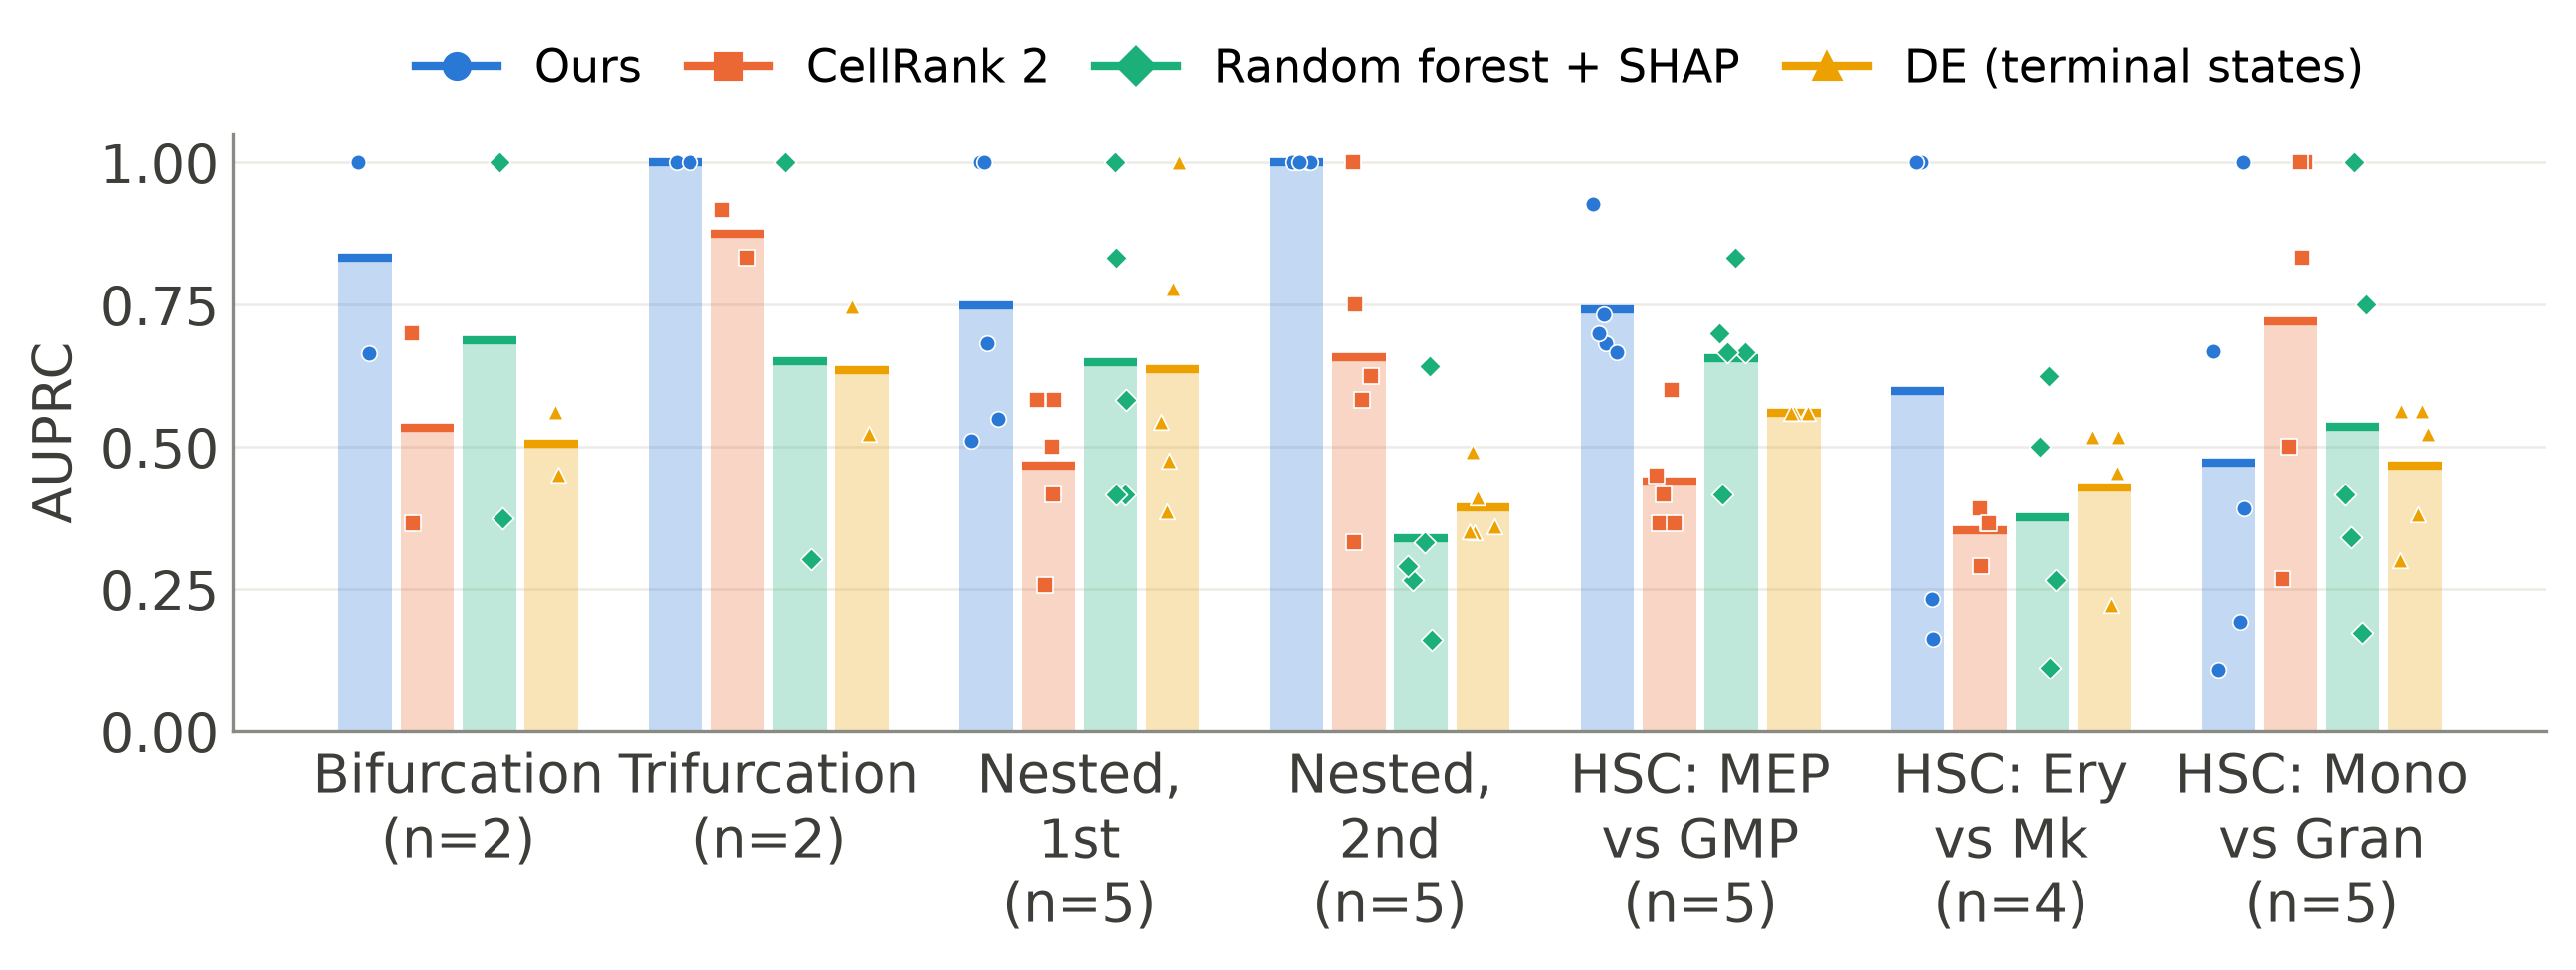

In [86]:
DECISIONS = [("Bifurcation", "BF-D1"), ("Trifurcation", "TF-D1"), ("Nested,\n1st", "CBF-D1"),
             ("Nested,\n2nd", "CBF-D2"), ("HSC: MEP\nvs GMP", "HSC-D1"), ("HSC: Ery\nvs Mk", "HSC-D2"),
             ("HSC: Mono\nvs Gran", "HSC-D3")]
grouped_figure([(lab, d.setting == s) for lab, s in DECISIONS], ["OURS_v2"] + COMPETITORS, "fig4_per_decision",
               width=10.0, height=2.6)

## 8. Figure 5: runtime
Version 2, one decision of the bifurcation network, 2 CPU cores (`scaling_v2.py`; cloud workspace, 5 Nov 2026).
Left: genes added as noisy copies of existing genes (500 cells); exact method vs the real-data settings (interventions
on the top 300 genes, at most 300 undecided cells). Right: more cells per trajectory (exact method). Measured on 2 CPU cores; the step that dominates is fitting one sparse regression per gene, so
runtime grows roughly with the cube of the number of genes; the fast settings reduce the number of
interventions and cells, not the number of regressions.

,variant,genes,cells,total_s
0,exact,100,500,0.4
1,exact,200,500,1.8
2,exact,400,500,9.6
3,exact,800,500,56.9
4,exact,1600,500,308.4
5,"fast (300 genes, 300 cells)",400,500,9.6
6,"fast (300 genes, 300 cells)",800,500,25.8
7,"fast (300 genes, 300 cells)",1600,500,102.8
8,"fast (300 genes, 300 cells)",3200,500,458.8


,variant,genes,cells,total_s
0,exact,94,500,0.4
1,exact,94,2000,1.1
2,exact,94,4000,2.9


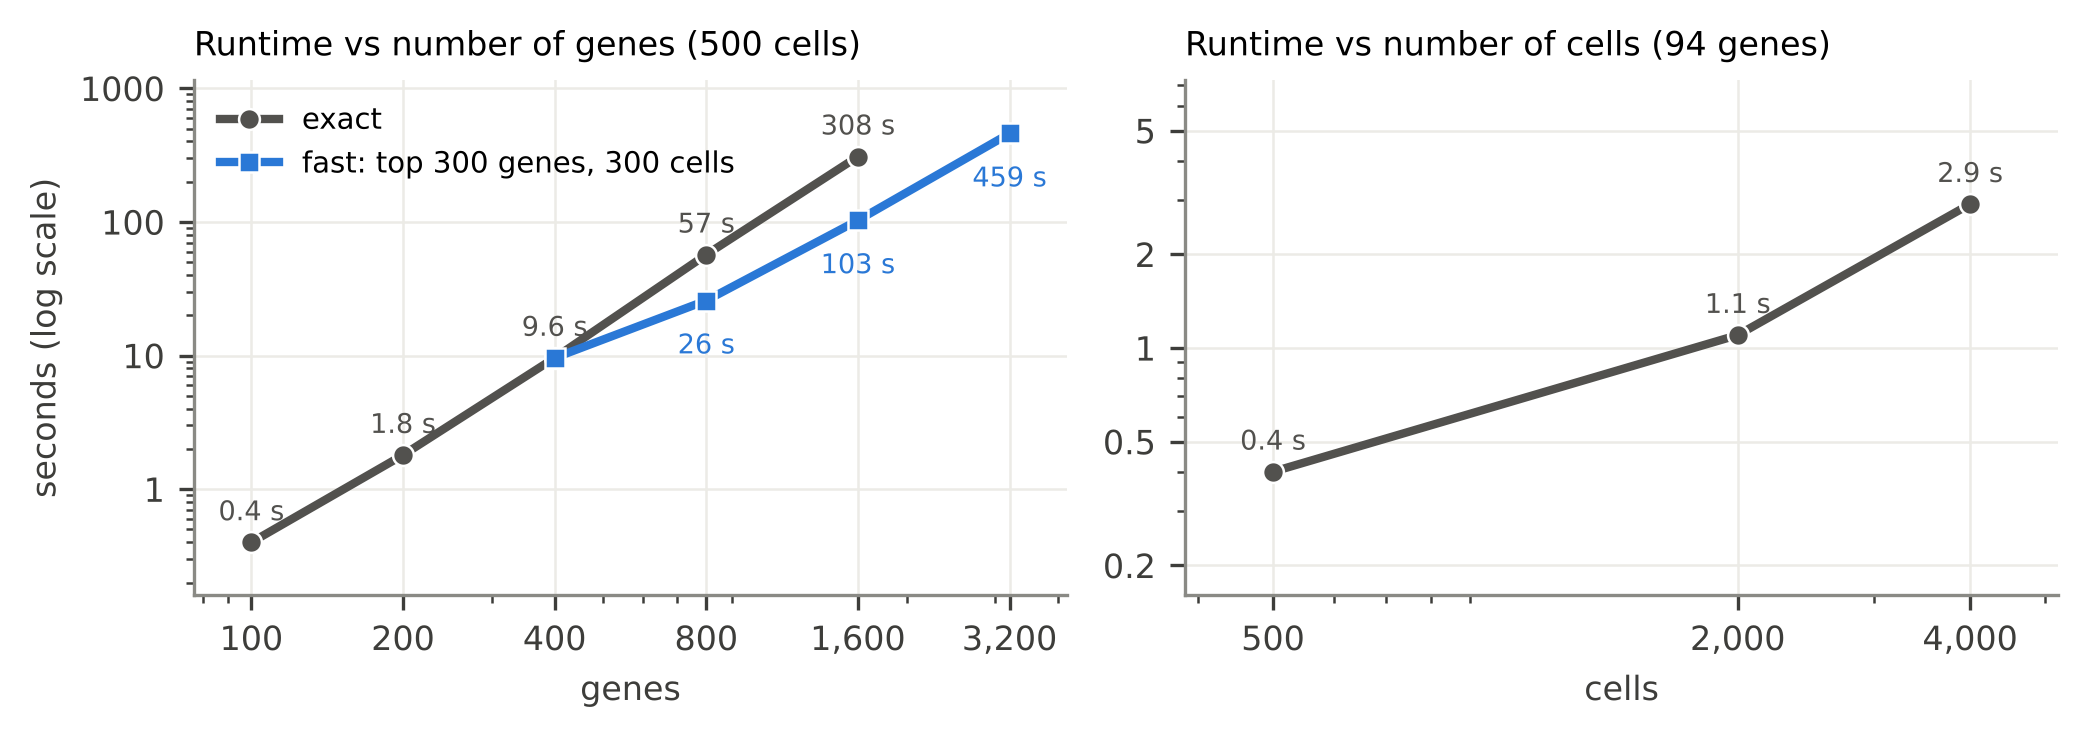

In [8]:
from matplotlib.ticker import NullFormatter, FuncFormatter
sg = pd.read_csv(RES / "scaling_v2_genes.csv"); sc = pd.read_csv(RES / "scaling_v2_cells.csv")
display(sg); display(sc)


def fig5():
    blue, grey = METHODS["OURS_v2"][1], "#52514e"
    fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.5))
    # (axis, data, x, colour, marker, legend label, value labels above (+) or below (-) the points)
    series = [(axes[0], sg[sg.variant == "exact"], "genes", grey, "o", "exact", 7),
              (axes[0], sg[sg.variant != "exact"], "genes", blue, "s", "fast: top 300 genes, 300 cells", -11),
              (axes[1], sc, "cells", grey, "o", "exact", 7)]
    for ax, df, x, col, mar, lab, dy in series:
        ax.plot(df[x], df.total_s, color=col, lw=2, zorder=2, label=lab, marker=mar, markersize=5,
                markeredgecolor="white", markeredgewidth=0.6)
        for xi, yi in zip(df[x], df.total_s):
            if dy < 0 and xi in set(sg[sg.variant == "exact"].genes) and xi <= 400:
                continue                                   # same as exact (all genes are candidates): label once
            ax.annotate(f"{yi:.0f} s" if yi >= 10 else f"{yi:.1f} s", (xi, yi), textcoords="offset points",
                        xytext=(0, dy), ha="center", va="center", fontsize=6.5, color=col)
    for ax, x, title in [(axes[0], "genes", "Runtime vs number of genes (500 cells)"),
                         (axes[1], "cells", "Runtime vs number of cells (94 genes)")]:
        df = sg if x == "genes" else sc
        ax.set_xscale("log"); ax.set_yscale("log")
        xt = sorted(df[x].unique()); ax.set_xticks(xt); ax.set_xticklabels([f"{int(v):,}" for v in xt])
        ax.xaxis.set_minor_formatter(NullFormatter()); ax.yaxis.set_minor_formatter(NullFormatter())
        lo, hi = df.total_s.min() / 2.5, df.total_s.max() * 2.5
        ax.set_yticks([t for t in [0.1, 0.2, 0.5, 1, 2, 5, 10, 20, 50, 100, 200, 500, 1000] if lo <= t <= hi]
                      if x == "cells" else [t for t in [0.1, 1, 10, 100, 1000] if lo <= t <= hi])
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
        ax.set_ylim(lo, hi); ax.set_xlim(min(xt) / 1.3, max(xt) * 1.3)
        ax.set_xlabel(x); ax.set_title(title, fontsize=8, loc="left")
        ax.grid(color=GRID_C, lw=0.6); ax.set_axisbelow(True)
    axes[0].set_ylabel("seconds (log scale)")
    axes[0].legend(loc="upper left", frameon=False, fontsize=7)
    fig.tight_layout()
    save(fig, "fig5_runtime_scaling")


fig5()

## 9. Speed-ups: fast vs exact
The speed-ups intervene only on the top-N genes by fate correlation and on at most M undecided cells. Checked with
deliberately strict settings (30 genes, 100 cells) on the 44 held-out decisions against the exact version 2
(`stress_v2.py` → `fast_vs_exact_v2.csv`). Real data uses 300 genes (or all TFs) and 300 cells.

In [9]:
fe = pd.read_csv(RES / "fast_vs_exact_v2.csv")
fe["setting"] = fe.model + "-" + fe.decision
display(fe.groupby("setting")[["auprc_exact", "auprc_fast"]].mean().round(2))
diff = fe.auprc_fast - fe.auprc_exact
nz = diff[diff != 0]
print(f"{len(fe)} decisions: mean exact {fe.auprc_exact.mean():.3f}, fast {fe.auprc_fast.mean():.3f}; "
      f"within 0.05 in {(diff.abs() < 0.05).sum()}/{len(fe)}; worse by >0.1 in {(diff < -0.1).sum()}; "
      f"Wilcoxon p = {wilcoxon(nz).pvalue if len(nz) > 5 else float('nan'):.2f}")

,auprc_exact,auprc_fast
setting,,
BF-D1,0.89,0.89
CBF-D1,0.75,0.75
CBF-D2,1.00,1.00
HSC-D1,0.74,0.74
HSC-D2,0.60,0.65
HSC-D3,0.47,0.47
TF-D1,1.00,1.00


44 decisions: mean exact 0.821, fast 0.825; within 0.05 in 43/44; worse by >0.1 in 0; Wilcoxon p = 0.84


## 10. Real data: LARRY and Nestorowa
Same colours and markers as above. **Choose the methods in `REAL_METHODS`** (ours is always first; any keys of
`METHODS`; CellOracle and CEFCON exist only here). Ours is the TF variant (`OURS_v2_TF`) when genes are ranked
among transcription factors and the default variant (`OURS_v2_fast`) when ranked among all genes, as in the
paper table.

**LARRY** (`larry_bootstrap.csv`; Weinreb 2020, in vitro, neutrophil vs monocyte): AUPRC of early fate-predictive
genes (defined from the lineage barcodes) against late markers. Bars = mean over the three 8,000-cell samples,
points = the samples, shaded = chance (share of early genes).

**Nestorowa** (`nestorowa_eval*.csv`; MegE vs Ly/My): ranks of the six core regulators (Gata1, Klf1, Tal1, Spi1,
Cebpa, Ikzf1) among the 165 transcription factors. Points = regulators (labelled), short bar = median rank
(ties averaged), dashed line = top 20; numbers on top = core regulators in the top 20.

mean             std          
ranked_among                        TFs all genes   TFs all genes
method                                                           
CEFCON                             0.37      0.36  0.04      0.01
CellOracle                         0.63      0.31  0.08      0.02
CellRank 2                         0.56      0.33  0.05      0.02
Ours                               0.70      0.49  0.01      0.01
Absorption corr., undecided cells  0.80      0.60  0.09      0.13
DE (terminal states)               0.49      0.28  0.04      0.00
Fate correlation                   0.51      0.29  0.00      0.01
Fate corr., undecided cells        0.57      0.40  0.00      0.03
Observational counterfactuals      0.54      0.38  0.04      0.03
Random                             0.38      0.22  0.13      0.01
Random forest + SHAP               0.57      0.36  0.01      0.01

KeyError: 'CellOracle'

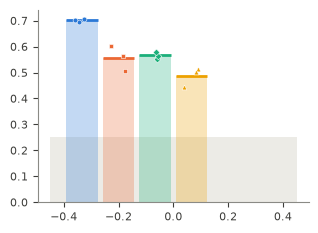

In [88]:
REAL_METHODS = ["CellRank", "rf_shap_fixed", "de_terminal", "CellOracle", "CEFCON"]
OURS_REAL = {"TFs": "OURS_v2_TF", "all genes": "OURS_v2_fast"}   # our variant per gene space

lb = pd.read_csv(RES / "larry_bootstrap.csv")
lb = lb[~lb.method.str.startswith("OURS") | lb.apply(lambda r: r.method == OURS_REAL[r.ranked_among], axis=1)]
lb = lb.assign(method=lb.method.where(~lb.method.str.startswith("OURS"), "OURS_v2"))
nes = pd.concat([pd.read_csv(RES / f) for f in ["nestorowa_eval.csv", "nestorowa_eval_competitors.csv",
                                                "nestorowa_eval_cellrank.csv"]]).query("ranked_among == 'TFs'")
nes = nes[~nes.method.str.startswith("OURS") | (nes.method == OURS_REAL["TFs"])]
nes = nes.assign(method=nes.method.where(~nes.method.str.startswith("OURS"), "OURS_v2")).set_index("method")
CORE = ["Gata1", "Klf1", "Tal1", "Spi1", "Cebpa", "Ikzf1"]
N_TF = int(nes.n_genes.iloc[0])
display(lb.pivot_table(index="method", columns="ranked_among", values="auprc", aggfunc=["mean", "std"]).round(2)
          .rename(index=LABEL))


def fig_larry(methods, seed=0):
    rng = np.random.default_rng(seed)
    n = len(methods); bw = 0.8 / n
    fig, ax = plt.subplots(figsize=(3.5, 2.5))
    for i, space in enumerate(["TFs", "all genes"]):
        sub = lb[lb.ranked_among == space]
        ch = sub.chance.iloc[0]
        ax.fill_between([i - 0.45, i + 0.45], 0, ch, color=GRID_C, lw=0, zorder=0)
        for j, m in enumerate(methods):
            y = sub[sub.method == m].auprc.values
            if len(y) == 0:
                continue
            _, col, mar = METHODS[m]
            x = i + (j - (n - 1) / 2) * bw
            ax.bar(x, y.mean(), bw * 0.86, color=col, alpha=0.28, edgecolor="none", zorder=2)
            ax.hlines(y.mean(), x - bw * 0.43, x + bw * 0.43, colors=col, lw=2, zorder=3)
            ax.scatter(x + rng.uniform(-bw * 0.2, bw * 0.2, len(y)), y, s=12, marker=mar, color=col,
                       edgecolors="white", linewidths=0.4, zorder=4)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["ranked among TFs", "ranked among all genes"])
    ax.set_xlim(-0.55, 1.55); ax.set_ylim(0, 1.0); ax.set_ylabel("AUPRC, early vs late genes")
    ax.yaxis.grid(True, color=GRID_C, lw=0.6); ax.set_axisbelow(True); ax.tick_params(axis="x", length=0)
    h = [plt.Line2D([], [], color=METHODS[m][1], marker=METHODS[m][2], lw=2, markersize=5, label=METHODS[m][0])
         for m in methods] + [plt.Rectangle((0, 0), 1, 1, color=GRID_C, label="chance")]
    ax.legend(handles=h, ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False, fontsize=6.5,
              handlelength=1.6, columnspacing=1.0)
    save(fig, "fig_larry")


def fig_nestorowa(methods, label_genes=True, min_gap=0.085):
    """min_gap: smallest vertical distance between gene labels, in log10 units (labels are spread to keep it)."""
    fig, ax = plt.subplots(figsize=(3.5, 2.7))
    for i, m in enumerate(methods):
        _, col, mar = METHODS[m]
        r = dict(t.split(":") for t in nes.loc[m, "ranks"].split())
        ranks = pd.Series({g: int(r[g]) for g in CORE})
        ax.scatter(np.full(len(ranks), i), ranks.values, s=16, marker=mar, color=col, edgecolors="white",
                   linewidths=0.4, zorder=4)
        ax.hlines(nes.loc[m, "core_median_rank"], i - 0.3, i + 0.3, colors=col, lw=2, zorder=3)
        ax.text(i, 0.62, f"{int((ranks <= 20).sum())}/6", ha="center", va="center", fontsize=7, color=INK2)
        if label_genes:
            # one label per rank (tied genes share it), then push labels apart in log space
            groups = ranks.groupby(ranks).apply(lambda s: ", ".join(s.index)).sort_index()
            pos = np.log10(groups.index.values.astype(float)); lab = pos.copy()
            for k in range(1, len(lab)):
                lab[k] = max(lab[k], lab[k - 1] + min_gap)
            for (rk, text), y0, y1 in zip(groups.items(), pos, lab):
                ax.annotate(text, (i, 10 ** y0), xytext=(i + 0.12, 10 ** y1), va="center", fontsize=5, color=INK2,
                            arrowprops=dict(arrowstyle="-", color=GRID_C, lw=0.5) if y1 - y0 > 0.02 else None)
    ax.axhline(20.5, color=AXIS_C, ls=(0, (3, 2)), lw=0.8, zorder=1)
    ax.text(-0.55, 21.5, "top 20", ha="left", va="top", fontsize=6, color=AXIS_C)
    ax.set_yscale("log"); ax.set_ylim(N_TF, 0.5)
    ax.set_yticks([1, 2, 5, 10, 20, 50, 100]); ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:g}"))
    ax.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
    ax.set_ylabel(f"rank among {N_TF} TFs (log scale)")
    ax.set_xticks(range(len(methods)))
    ax.set_xticklabels([SHORT[m] for m in methods], rotation=35, ha="right", rotation_mode="anchor", fontsize=7)
    ax.set_xlim(-0.6, len(methods) - 0.15)
    ax.yaxis.grid(True, color=GRID_C, lw=0.6); ax.set_axisbelow(True); ax.tick_params(axis="x", length=0)
    save(fig, "fig_nestorowa")


fig_larry(["OURS_v2"] + REAL_METHODS)
fig_nestorowa(["OURS_v2"] + REAL_METHODS)

## 11. Ablation panels, one PNG per design choice
Same 44 held-out decisions. Each panel changes one design choice and keeps the rest at the chosen setting (blue; dashed line = its mean). Grey bars = alternatives, points = individual decisions, * = paired Wilcoxon p < 0.05 against the chosen setting.
Sources: `ablation_v2.csv`, `ablation_v2_extra.csv` (no timing rule, K = 1/10, onset threshold 0.1/0.3; `ablation_v2_extra.py`), `v2_heldout.csv` (K = 5, max-shift scoring), `readout_heldout.csv` (fate predictors).
Each panel is saved separately as `../figures/ablation/ablation_<choice>.png`, plus a legend (`ablation_legend.png`), so they can be arranged freely. All images, including the legend, have exactly the same size (3.5 × 2.3 in, 300 dpi), the same y-axis and the same bar width; panels with fewer bars are centred.

In [11]:
KEY = ["dataset", "decision"]
def _col(df, **q):
    m = np.ones(len(df), bool)
    for k, v in q.items():
        m &= (df[k] == v).values
    return df[m].set_index(KEY)["auprc_vs_markers"]

_a, _x = pd.read_csv(RES / "ablation_v2.csv"), pd.read_csv(RES / "ablation_v2_extra.csv")
_h, _r = pd.read_csv(RES / "v2_heldout.csv"), pd.read_csv(RES / "readout_heldout.csv")
ref = _col(_a, variant="v2")
_root = pd.concat([_col(_a, variant=f"pt_dpt_root_s{s}") for s in range(3)], axis=1).mean(axis=1)
PANELS = {  # file name: (title, [(tick label, per-decision AUPRC, is chosen setting)])
    "timing_rule": ("Timing rule", [("with", ref, True), ("without", _col(_x, variant="no_timing"), False)]),
    "rollout_steps": ("Rollout steps $K$", [("0", _col(_a, variant="K0"), False), ("1", _col(_x, variant="K1"), False),
                      ("3", ref, True), ("5", _col(_h, K=5, mode="perfate"), False), ("10", _col(_x, variant="K10"), False)]),
    "onset_threshold": ("Onset threshold", [("0.1", _col(_x, variant="frac0.1"), False), ("0.2", ref, True),
                        ("0.3", _col(_x, variant="frac0.3"), False)]),
    "pseudotime": ("Pseudotime", [("DPT", ref, True), ("shifted\nroot", _root, False),
                   ("PCA\ndist.", _col(_a, variant="pt_pca_dist"), False), ("true\ntime", _col(_a, variant="pt_true"), False)]),
    "cells": ("Cells intervened on", [("undecided", ref, True), ("all non-\nterminal", _col(_a, variant="region_all"), False)]),
    "scoring_rule": ("Scoring rule", [("per-fate\nrank", ref, True), ("max\nshift", _col(_h, K=3, mode="prob"), False)]),
    "fate_predictor": ("Fate predictor", [("LR", ref, True), ("PCA\n+ LR", _col(_r, readout="pca_logreg"), False),
                       ("soft\nlabels", _col(_r, readout="soft_logreg"), False), ("graph", _col(_r, readout="knn_absorb"), False)]),
}
BLUE, GREY_A = METHODS["OURS_v2"][1], AXIS_C
STYLE = {"font.family": "DejaVu Sans", "font.size": 8, "axes.spines.top": False, "axes.spines.right": False,
         "axes.edgecolor": "#8a8a85", "xtick.color": "#3d3d3a", "ytick.color": "#3d3d3a", "axes.labelcolor": "#3d3d3a",
         "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white"}
ABL = FIG / "ablation"; ABL.mkdir(exist_ok=True)
BAR_IN, LEFT_IN, H_IN = 0.55, 0.62, 2.3     # inches per bar, y-axis margin, panel height (same for every panel)

def ablation_panel(name, title, items, seed=0):
    rng = np.random.default_rng(seed)
    nmax = max(len(it) for _, it in PANELS.values())       # every panel gets the canvas of the widest one
    w = LEFT_IN + BAR_IN * (nmax + 0.2)
    pad = (nmax - len(items)) / 2                              # centre panels with fewer bars
    with plt.rc_context(STYLE):
        fig = plt.figure(figsize=(w, H_IN))
        ax = fig.add_axes([LEFT_IN / w, 0.24, 1 - (LEFT_IN + 0.05) / w, 0.62])
        ax.axhline(ref.mean(), color=BLUE, ls=(0, (3, 2)), lw=0.8, zorder=1)
        rows = []
        for i, (lab, s, chosen) in enumerate(items):
            y = s.reindex(ref.index); assert y.notna().all(), (name, lab)
            c = BLUE if chosen else GREY_A
            ax.bar(i, y.mean(), 0.72, color=c, alpha=0.25, edgecolor="none", zorder=2)
            ax.hlines(y.mean(), i - 0.36, i + 0.36, colors=c, lw=2, zorder=3)
            ax.scatter(i + rng.uniform(-0.2, 0.2, len(y)), y, s=7, color=c, edgecolors="white", linewidths=0.3, zorder=4)
            pv = np.nan if chosen else wilcoxon(ref, y).pvalue
            if pv < 0.05:
                ax.text(i, 1.05, "*", ha="center", va="bottom", fontsize=10, color="#3d3d3a")
            rows.append({"choice": title.replace("$", ""), "setting": lab.replace("\n", " "), "chosen": chosen,
                         "mean AUPRC": y.mean(), "chosen better": None if chosen else int((ref > y).sum()),
                         "chosen worse": None if chosen else int((ref < y).sum()), "Wilcoxon p": pv})
        ax.set_xticks(range(len(items))); ax.set_xticklabels([it[0] for it in items], fontsize=7)
        ax.set_xlim(-0.6 - pad, len(items) - 0.4 + pad); ax.set_ylim(0, 1.12); ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
        ax.set_ylabel("AUPRC"); ax.set_title(title, fontsize=8, pad=12)
        ax.tick_params(axis="x", length=0)
        ax.yaxis.grid(True, color="#ecebe6", lw=0.6); ax.set_axisbelow(True)
        fig.savefig(ABL / f"ablation_{name}.png", dpi=300)
        plt.close(fig)
    return rows

def ablation_legend():
    with plt.rc_context(STYLE):
        nmax = max(len(it) for _, it in PANELS.values())
        fig = plt.figure(figsize=(LEFT_IN + BAR_IN * (nmax + 0.2), H_IN))   # same size as the panels
        h = [plt.Line2D([], [], color=BLUE, lw=2, marker="o", markersize=6, label="chosen setting"),
             plt.Line2D([], [], color=GREY_A, lw=2, marker="o", markersize=6, label="alternative"),
             plt.Line2D([], [], color="#3d3d3a", lw=0, marker="$*$", markersize=8, label="Wilcoxon $p<0.05$")]
        fig.legend(handles=h, loc="center", frameon=False, fontsize=15)
        fig.savefig(ABL / "ablation_legend.png", dpi=300)
        plt.close(fig)

summary = pd.DataFrame([r for name, (title, items) in PANELS.items() for r in ablation_panel(name, title, items)])
ablation_legend()
display(summary.round(3))
print("saved to", ABL)


,choice,setting,chosen,mean AUPRC,chosen better,chosen worse,Wilcoxon p
0,Timing rule,with,True,0.82,NaN,NaN,NaN
1,Timing rule,without,False,0.37,39.0,4.0,0.00e+00
2,Rollout steps K,0,False,0.29,40.0,3.0,0.00e+00
3,Rollout steps K,1,False,0.75,13.0,7.0,4.00e-02
4,Rollout steps K,3,True,0.82,NaN,NaN,NaN
5,Rollout steps K,5,False,0.83,6.0,10.0,5.01e-01
6,Rollout steps K,10,False,0.77,14.0,10.0,9.70e-02
7,Onset threshold,0.1,False,0.72,21.0,8.0,2.20e-02
8,Onset threshold,0.2,True,0.82,NaN,NaN,NaN
9,Onset threshold,0.3,False,0.82,8.0,12.0,7.51e-01


saved to /home/claude/driver_benchmark/figures/ablation


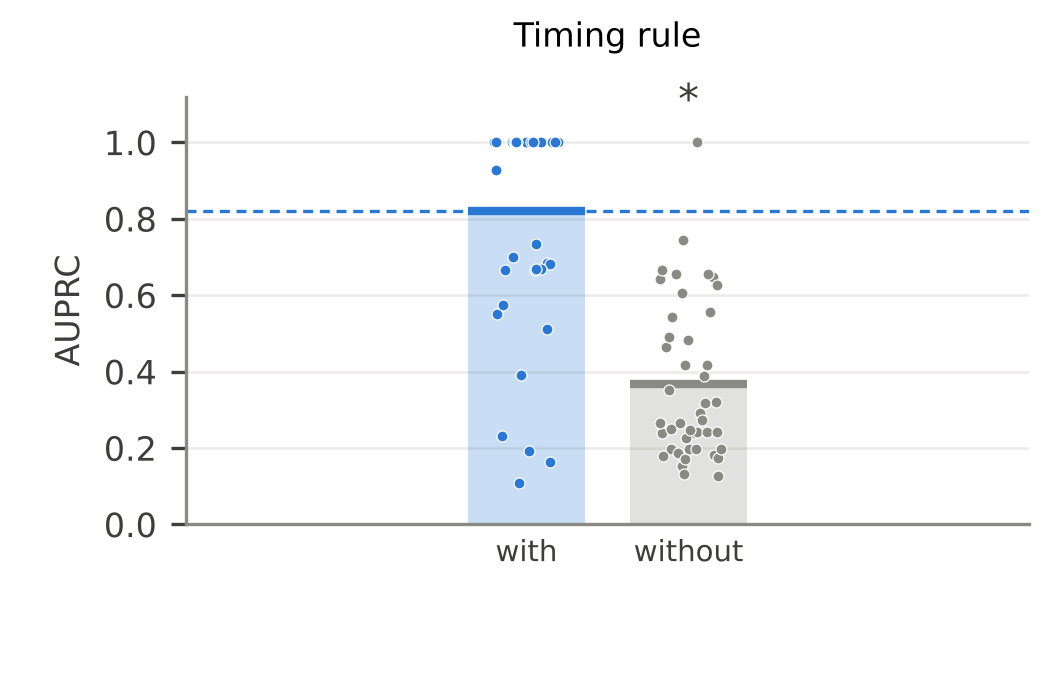

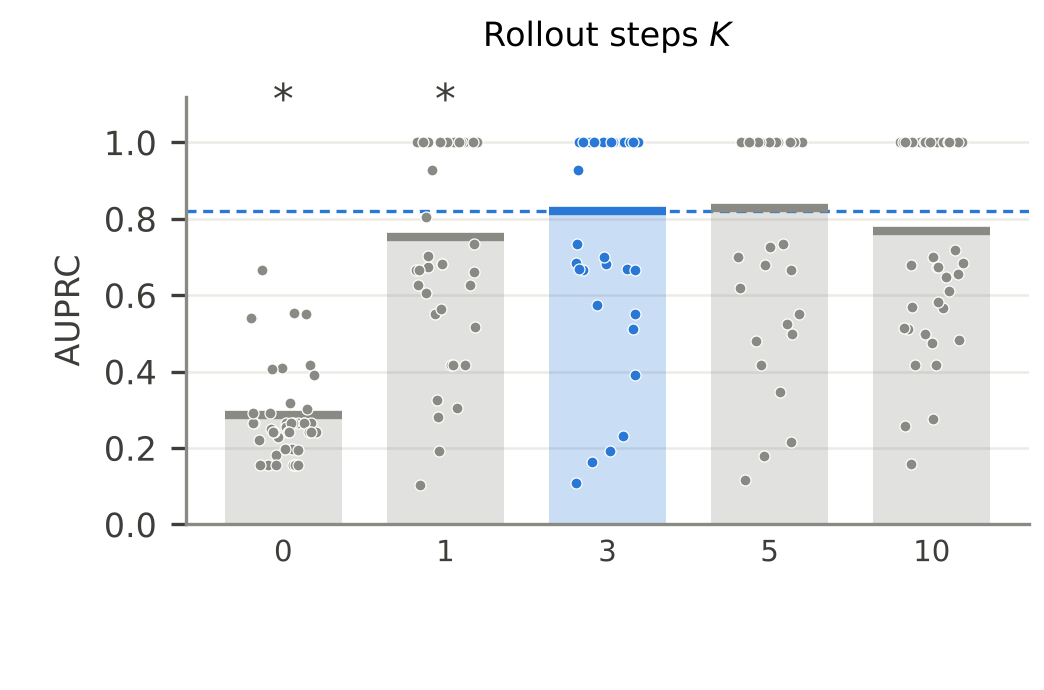

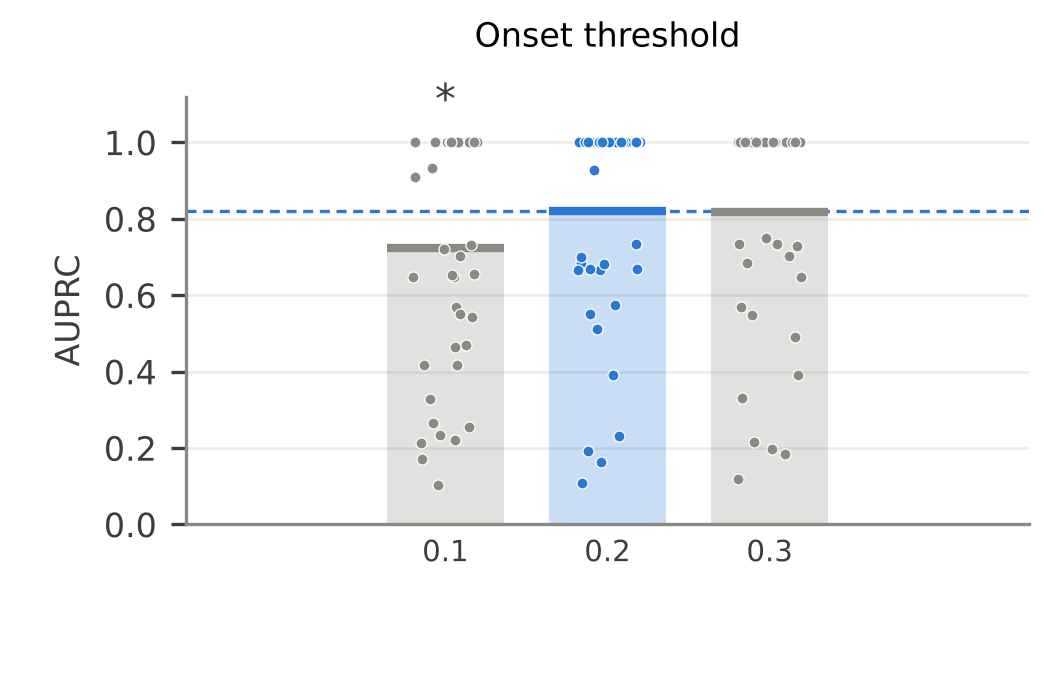

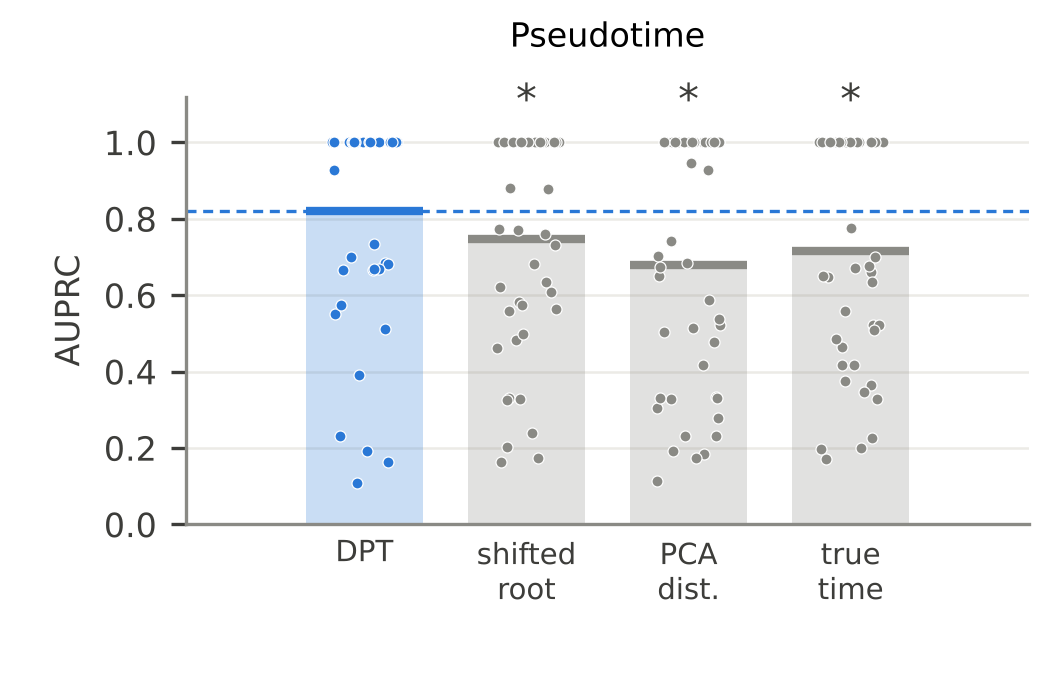

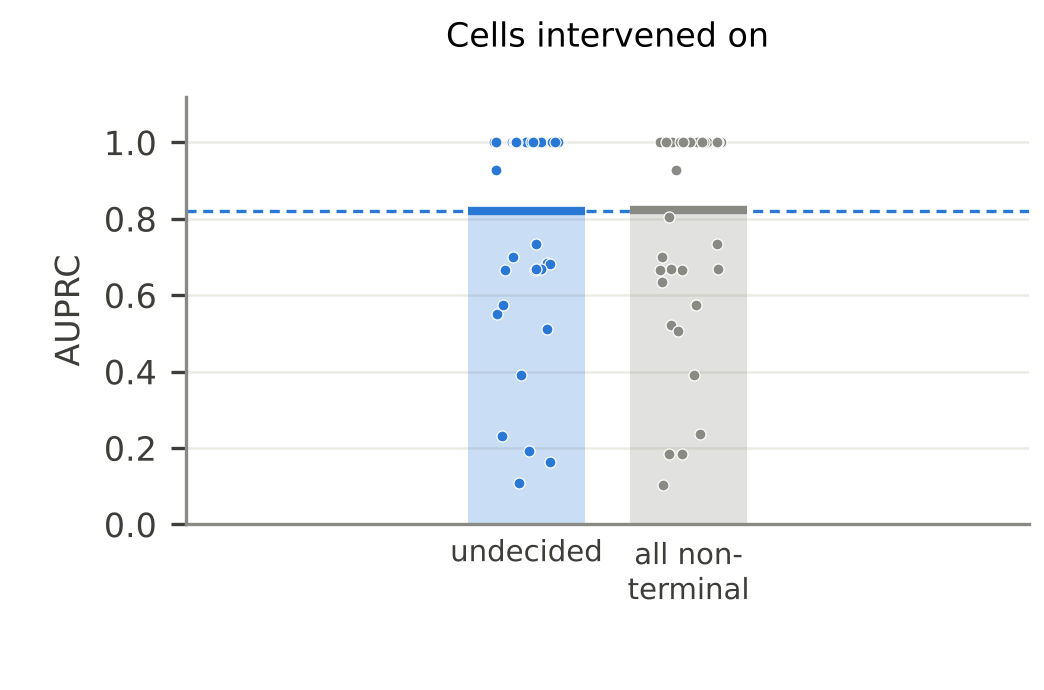

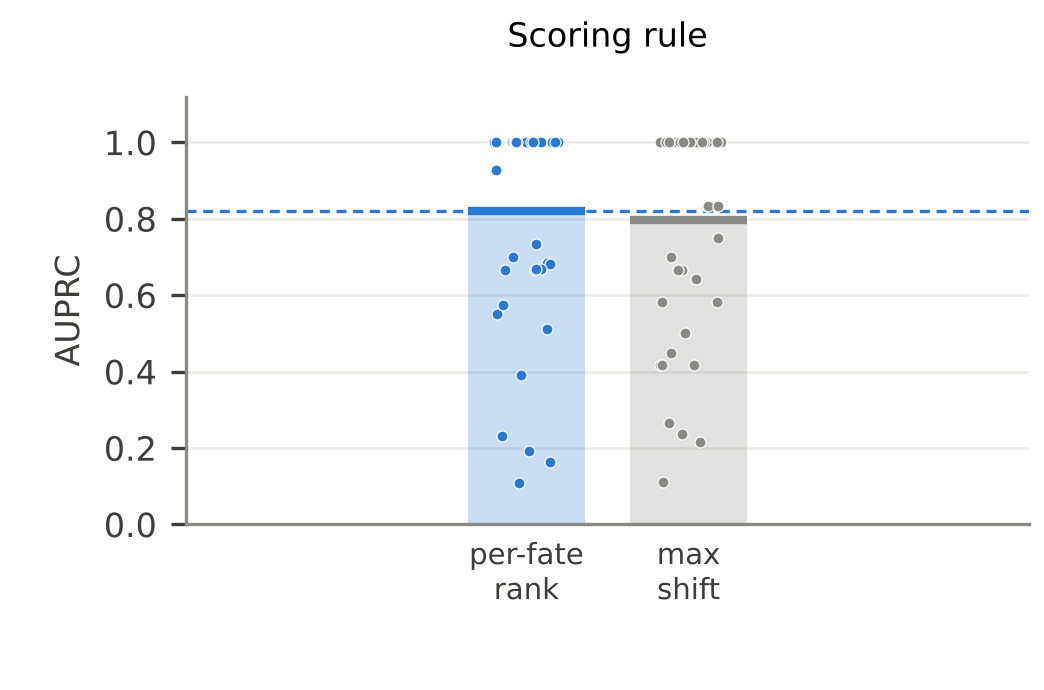

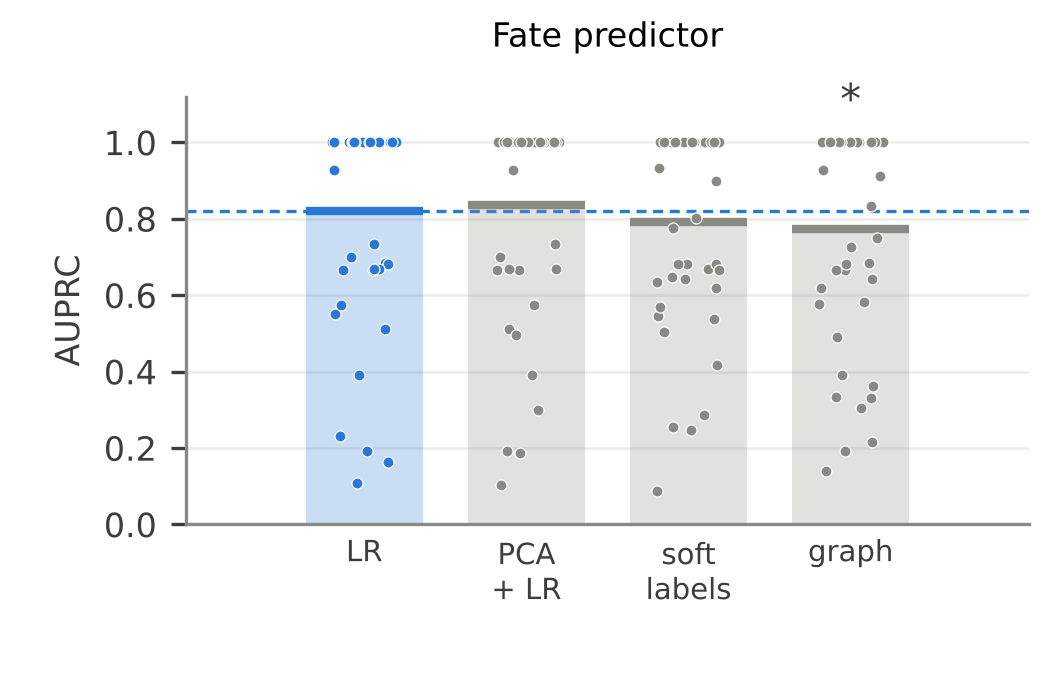

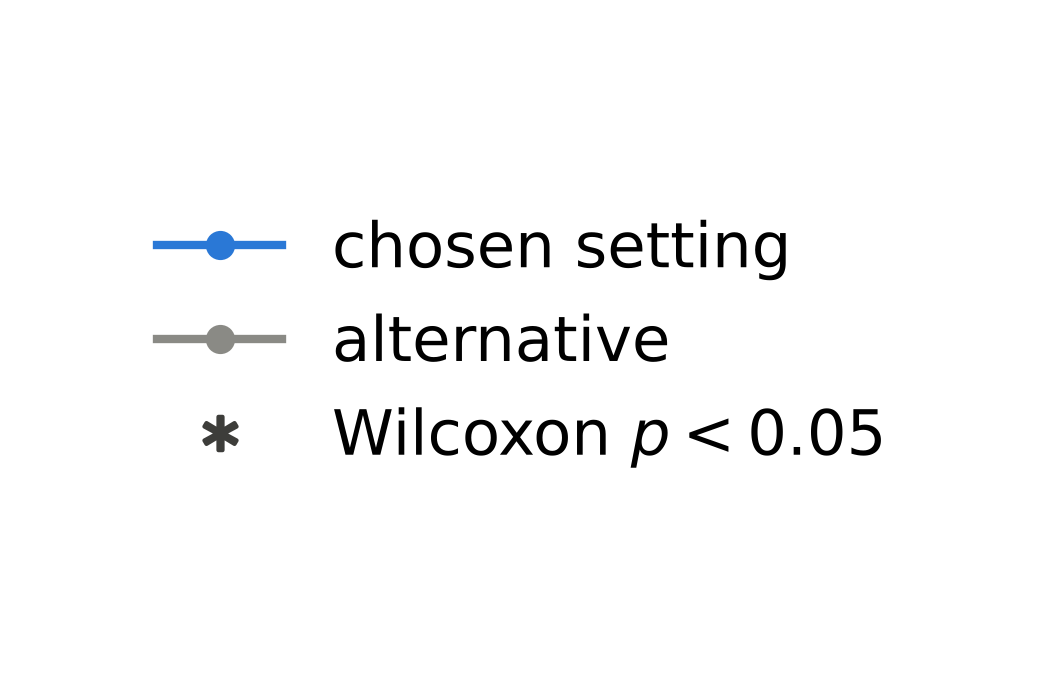

In [12]:
for name in list(PANELS) + ["legend"]:
    display(Image(filename=str(ABL / f"ablation_{name}.png"), width=260))


## Depth experiment: random nested lineage trees (17 Nov 2026)

Random binary trees grown with split probability p (0.8, 0.5) and exactly D = 1-4 nested splits on the deepest path, 10 networks per (p, D). Simulated with `simulate_tree.py`, scored with `eval_tree.py` (frozen v2 method, nothing tuned). Cells at t = 0 are dropped before scoring. Run everything with `bash experiments/tree_depth/run_tree_all.sh`.

*Top:* one point per network (mean over its decisions). *Bottom:* every decision at its own level in the tree.

In [ ]:
import subprocess, sys
from IPython.display import Image, display
subprocess.run([sys.executable, 'experiments/tree_depth/fig_tree_depth.py'], cwd='..', check=True)
display(Image('../figures/fig_tree_depth.png', width=900))
display(Image('../figures/fig_tree_level.png', width=900))